In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:


# df = pd.read_csv(r'D:\proj\howamachinelearns\fruitsandveggies\ProductPriceIndex.csv')
df = pd.read_csv(r'/Users/christianmarchello/Documents/howamachinelearns/fruitsandveggies/ProductPriceIndex.csv')
currency_columns = ['farmprice', 'atlantaretail', 'chicagoretail', 'losangelesretail','newyorkretail']
for col in currency_columns:
     df[col] = df[col].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False)
     df[col] = pd.to_numeric(df[col])
     
     
print(df.dtypes)

print(len(df))

productname          object
date                 object
farmprice           float64
atlantaretail       float64
chicagoretail       float64
losangelesretail    float64
newyorkretail       float64
averagespread        object
dtype: object
15766


In [5]:
###assignment


df_less_rows = df.loc[df['productname']=='Potatoes']

df_less_rows = df_less_rows.copy(deep="True")

print(df_less_rows)





      productname        date  farmprice  atlantaretail  chicagoretail  \
3        Potatoes  2019-05-19       1.50           5.32           5.14   
16       Potatoes  2019-05-12       1.50           5.07           5.14   
30       Potatoes  2019-05-05       1.60           5.07           5.14   
42       Potatoes  2019-04-28       1.60           4.97           5.14   
55       Potatoes  2019-04-21       1.60           4.97           4.31   
...           ...         ...        ...            ...            ...   
15701    Potatoes  1999-11-28       0.83           3.39           0.00   
15714    Potatoes  1999-11-21       0.83           3.51           0.00   
15723    Potatoes  1999-11-14       0.83           3.51           0.00   
15746    Potatoes  1999-11-07       0.83           3.51           0.00   
15757    Potatoes  1999-10-31       0.78           3.33           0.00   

       losangelesretail  newyorkretail averagespread  
3                  3.99           6.22       244.50%  
1

In [6]:
###splitting date column and assinging season

# seasons = {"spring":[3,4,5], "summer":[6,7,8], "fall":[9,10,11], "winter":[12,1,2]}


df_dates_split = df_less_rows.assign(
    year = lambda x: x["date"].str.split("-").str[0].astype(int),
    month = lambda x: x["date"].str.split("-").str[1].astype(int),
    day = lambda x: x["date"].str.split("-").str[2].astype(int)
)


        
print(df_dates_split)









      productname        date  farmprice  atlantaretail  chicagoretail  \
3        Potatoes  2019-05-19       1.50           5.32           5.14   
16       Potatoes  2019-05-12       1.50           5.07           5.14   
30       Potatoes  2019-05-05       1.60           5.07           5.14   
42       Potatoes  2019-04-28       1.60           4.97           5.14   
55       Potatoes  2019-04-21       1.60           4.97           4.31   
...           ...         ...        ...            ...            ...   
15701    Potatoes  1999-11-28       0.83           3.39           0.00   
15714    Potatoes  1999-11-21       0.83           3.51           0.00   
15723    Potatoes  1999-11-14       0.83           3.51           0.00   
15746    Potatoes  1999-11-07       0.83           3.51           0.00   
15757    Potatoes  1999-10-31       0.78           3.33           0.00   

       losangelesretail  newyorkretail averagespread  year  month  day  
3                  3.99           6.22

In [7]:
df_dates_split.loc[df_dates_split['month'].isin([3, 4, 5]), 'season'] = 'spring'
df_dates_split.loc[df_dates_split['month'].isin([6, 7, 8]), 'season'] = 'summer'
df_dates_split.loc[df_dates_split['month'].isin([9, 10, 11]), 'season'] = 'fall'
df_dates_split.loc[df_dates_split['month'].isin([12, 1, 2]), 'season'] = 'winter'

print(df_dates_split)



        

    

      productname        date  farmprice  atlantaretail  chicagoretail  \
3        Potatoes  2019-05-19       1.50           5.32           5.14   
16       Potatoes  2019-05-12       1.50           5.07           5.14   
30       Potatoes  2019-05-05       1.60           5.07           5.14   
42       Potatoes  2019-04-28       1.60           4.97           5.14   
55       Potatoes  2019-04-21       1.60           4.97           4.31   
...           ...         ...        ...            ...            ...   
15701    Potatoes  1999-11-28       0.83           3.39           0.00   
15714    Potatoes  1999-11-21       0.83           3.51           0.00   
15723    Potatoes  1999-11-14       0.83           3.51           0.00   
15746    Potatoes  1999-11-07       0.83           3.51           0.00   
15757    Potatoes  1999-10-31       0.78           3.33           0.00   

       losangelesretail  newyorkretail averagespread  year  month  day  season  
3                  3.99       

/var/folders/cs/j8zp0cms6vq0cmpk_cyy1kn00000gn/T/ipykernel_66174/1122427700.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'spring' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_dates_split.loc[df_dates_split['month'].isin([3, 4, 5]), 'season'] = 'spring'


In [68]:
### creating specific tables for each specific fruit/veggie

table_by_productname = {}

for key_value, grouped_df in df_less_rows.groupby('productname'):
    table_by_productname[key_value] = grouped_df.reset_index(drop=True)



# print(table_by_productname)
for key in table_by_productname:
    print("\nDataFrame for key:" +  key)
    print(table_by_productname[key])
    




DataFrame for key:Avocados
  productname        date  farmprice  atlantaretail  chicagoretail  \
0    Avocados  2019-05-19       1.23           1.16           1.82   
1    Avocados  2019-05-12       1.23           1.12           1.49   
2    Avocados  2019-05-05       1.01           1.25           1.57   

   losangelesretail  newyorkretail averagespread  year  month  day  season  
0              1.75           1.69        30.49%  2019      4   28  spring  
1              1.75           1.69        22.97%  2019      4   28  spring  
2              1.69           1.69        53.47%  2019      4   28  spring  

DataFrame for key:Broccoli Bunches
        productname        date  farmprice  atlantaretail  chicagoretail  \
0  Broccoli Bunches  2019-05-12       1.09           1.48           2.11   

   losangelesretail  newyorkretail averagespread  year  month  day  season  
0              1.16           1.48        42.89%  2019      4   28  spring  

DataFrame for key:Broccoli Crowns
     

In [69]:
cauliflower_table = table_by_productname["Cauliflower"].copy(deep=True) 
print(cauliflower_table)

   productname        date  farmprice  atlantaretail  chicagoretail  \
0  Cauliflower  2019-05-19       1.22           3.24           4.35   
1  Cauliflower  2019-05-12       2.74           3.24           4.35   
2  Cauliflower  2019-05-05       3.33           3.41           4.36   
3  Cauliflower  2019-04-28       3.23           3.41           3.43   

   losangelesretail  newyorkretail averagespread  year  month  day  season  
0              4.03           2.97       198.98%  2019      4   28  spring  
1              3.98           3.48        37.32%  2019      4   28  spring  
2              4.03           3.23        12.84%  2019      4   28  spring  
3              3.88           3.35         8.90%  2019      4   28  spring  


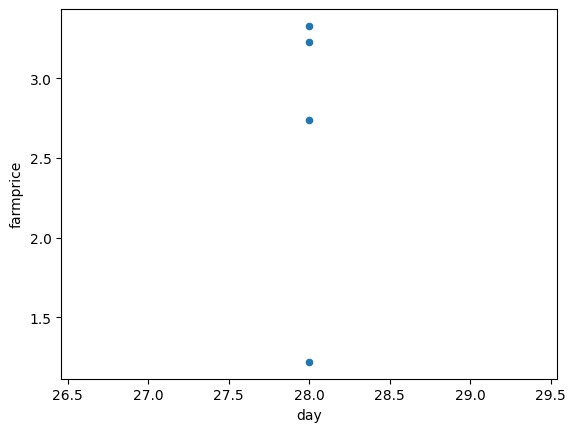

In [74]:
cauliflower_table.plot( kind='scatter',x='day', y='farmprice')

plt.show()

### Daily Potato Farm Prices by Day and Season

One thing is wouldn't it make more sense to use the median here


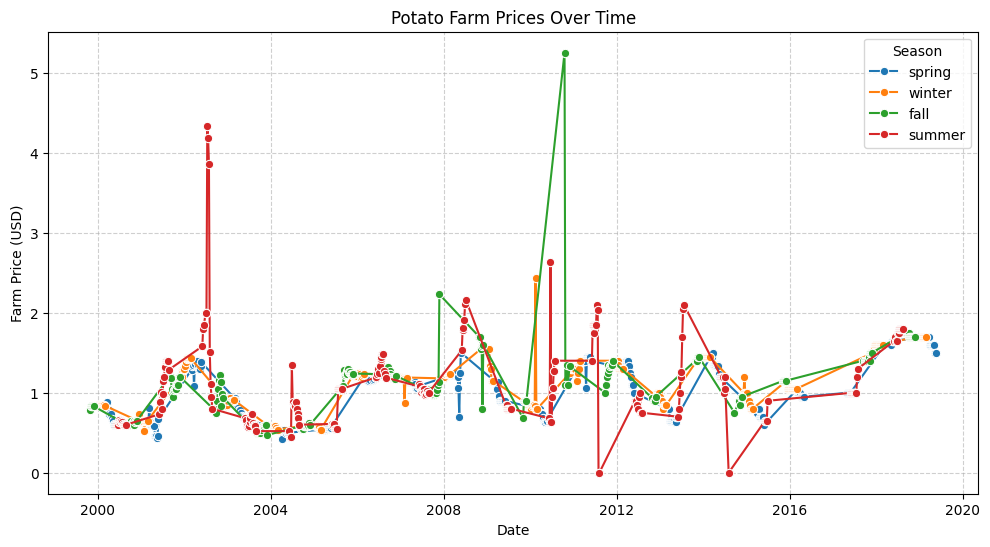

In [8]:
#('line', 'bar', 'barh', 'kde', 'density', 'area', 'hist', 'box', 'pie', 'scatter', 'hexbin')

# potatoes = df_dates_split[df_dates_split['season'] == "fall"].copy(deep=True)
potatoes = df_dates_split.copy(deep=True)

# print(specific_season)
# potatoes = potatoes.sort_values(by=['year', 'month', 'day'])
# print(potatoes)
# plt.figure(figsize=(10, 6))
# sns.lineplot(data=potatoes, x='day', y='farmprice', hue='season', marker='o')

# days = sorted(potatoes['day'].unique())
# plt.xticks(days, rotation=45)

# plt.title("Daily Potato Farm Prices by season")
# plt.xlabel("Day of Month")
# plt.ylabel("Farm Price (USD)")
# plt.grid(True, linestyle='--', alpha=0.6)
# plt.legend(title="season")


# plt.show()
# Ensure date is datetime type
potatoes['date'] = pd.to_datetime(potatoes['date'])

plt.figure(figsize=(12,6))
sns.lineplot(data=potatoes, x='date', y='farmprice', hue='season', marker='o')
years = sorted(potatoes['year'].unique())

# plt.xticks(years, rotation=45)

plt.title("Potato Farm Prices Over Time")
plt.xlabel("Date")
plt.ylabel("Farm Price (USD)")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title="Season")
plt.show()


### Monthly Potato Price Avg by Season (All time)


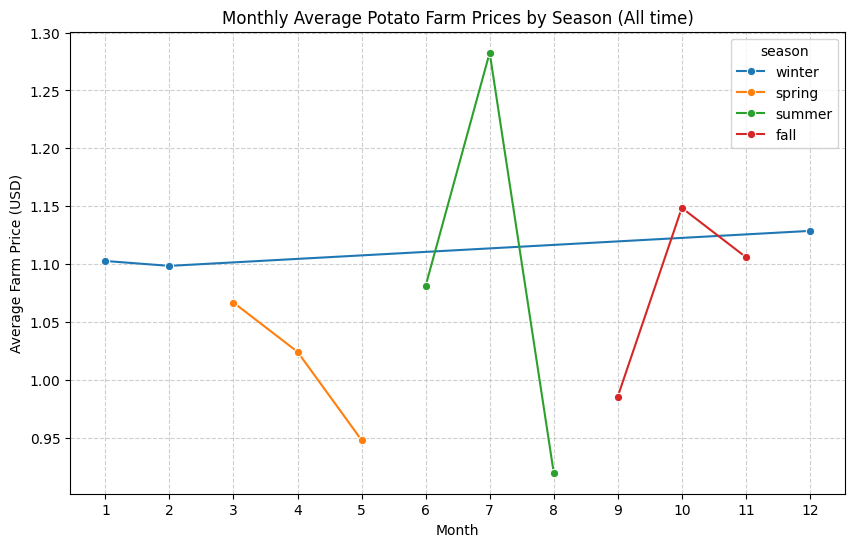

In [210]:
# Aggregate to monthly average farm prices
monthly_avg = (
    potatoes.groupby(['month', 'season'], as_index=False)['farmprice']
    .mean()
)



# Plot monthly averages grouped by year
plt.figure(figsize=(10, 6))
sns.lineplot(data=monthly_avg, x='month', y='farmprice', hue='season', marker='o')

plt.title("Monthly Average Potato Farm Prices by Season (All time)")
plt.xlabel("Month")
plt.ylabel("Average Farm Price (USD)")
plt.xticks(range(1, 13))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title="season")
plt.show()


### Yearly Average Potato Farm Prices by Season (All time)


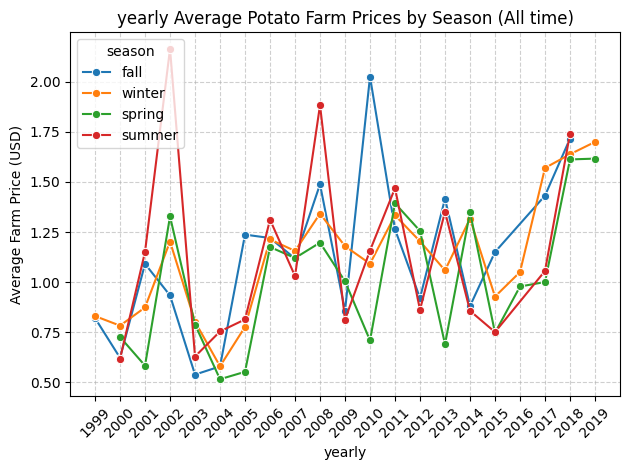

In [220]:
# Aggregate to yearly average farm prices
yearly_avg = (
    potatoes.groupby(['year', 'season'], as_index=False)['farmprice']
    .mean()
)



# Plot yearly averages grouped by year

sns.lineplot(data=yearly_avg, x='year', y='farmprice', hue='season', marker='o')

plt.title("yearly Average Potato Farm Prices by Season (All time)")
plt.xlabel("yearly")
plt.ylabel("Average Farm Price (USD)")
years = sorted(yearly_avg['year'].unique())
plt.xticks(years, rotation=45)  # rotation helps readability

plt.grid(True, linestyle='--', alpha=0.6)
# plt.xticks(range(1, 13))
# plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title="season")
plt.tight_layout()
plt.show()

### Now using all fruits and vegetables to generalize prices across farms and commercial locations
